In [2]:
import os
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tikzplotlib
import tqdm

In [3]:
out_dir = "/media/signet/9b222db5-110f-45ae-b7ca-0f12241ce80b/MOAN_LowRate_Video/fulleval_long/"
camps = os.listdir(out_dir)


dfs = []
for c in camps:
    for i in tqdm.trange(998):
        try:
            df = pd.read_csv(out_dir+c+f"/evaluate_data_{i}.csv")
            df['campaign'] = int(c.split('_')[1])
            df = df[["campaign", "seed", "epoch", "Acoustic", "Optical", "Wait", "Drop", "agent"]]
            df = df.groupby(["campaign", "seed", "epoch", "agent"]).sum().reset_index()
            df['Acoustic'] = df['Acoustic'].astype(float)
            df['Optical'] = df['Optical'].astype(float)
            df['Wait'] = df['Wait'].astype(float)
            df['Drop'] = df['Drop'].astype(float)
            for seed in df['seed'].unique():
                ac = df.loc[df['seed'] == seed, "Acoustic"]
                op = df.loc[df['seed'] == seed, "Optical"]
                wa = df.loc[df['seed'] == seed, "Wait"]
                dr = df.loc[df['seed'] == seed, "Drop"]
                tot = ac + op + wa + dr
                df.loc[df['seed'] == seed, "Acoustic"] = ac / tot
                df.loc[df['seed'] == seed, "Optical"] = op / tot
                df.loc[df['seed'] == seed, "Wait"] = wa / tot
                df.loc[df['seed'] == seed, "Drop"] = dr / tot
            dfs.append(df)
        except:
            continue
df = pd.concat(dfs)

100%|██████████| 998/998 [03:44<00:00,  4.45it/s]


/tmp/ipykernel_2126659/1054553793.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  throughput["Acoustic"] = throughput["Acoustic"].rolling(window=window_size, min_periods=1).mean()
/tmp/ipykernel_2126659/1054553793.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  throughput["Optical"] = throughput["Optical"].rolling(window=window_size, min_periods=1).mean()
/tmp/ipykernel_2126659/1054553793.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .

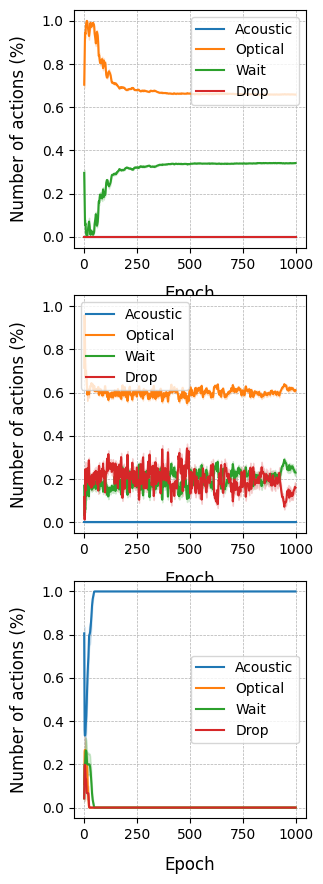

In [4]:
palette = sns.color_palette("tab10", 4)

import matplotlib.pylab as pylab
params = {'axes.labelsize': 12}
pylab.rcParams.update(params)

window_size = 40  # Define the window size for the moving average

fig, axes = plt.subplots(3, 1, figsize=(2.5*1.2, 3*3.5), sharey=True)
for agent_id in range(3):
    ax = axes[agent_id]
    throughput = df[df["agent"] == agent_id]
    plt.sca(ax)
    # Apply moving average
    throughput["Acoustic"] = throughput["Acoustic"].rolling(window=window_size, min_periods=1).mean()
    throughput["Optical"] = throughput["Optical"].rolling(window=window_size, min_periods=1).mean()
    throughput["Wait"] = throughput["Wait"].rolling(window=window_size, min_periods=1).mean()
    throughput["Drop"] = throughput["Drop"].rolling(window=window_size, min_periods=1).mean()
    
    sns.lineplot(data=throughput, x="epoch", y="Acoustic", label="Acoustic", ax=ax, color=palette[0])
    sns.lineplot(data=throughput, x="epoch", y="Optical", label="Optical", ax=ax, color=palette[1])
    sns.lineplot(data=throughput, x="epoch", y="Wait", label="Wait", ax=ax, color=palette[2])
    sns.lineplot(data=throughput, x="epoch", y="Drop", label="Drop", ax=ax, color=palette[3])
    
    plt.ylabel("Number of actions (%)", labelpad=10)
    plt.xlabel("Epoch", labelpad=10)
    plt.grid(True, linestyle='--', linewidth=0.5)
    if agent_id == 0:
        plt.legend()
tikzplotlib.save(f"/home/signet/test_out/actions_over_epochs.tex")
plt.savefig(f"actions_{agent_id}.pdf", bbox_inches='tight')
plt.show()


,epoch,campaign,seed,agent,Acoustic,Optical,Wait,Drop
0,2,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
1,4,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
2,6,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
3,8,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
4,10,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
5,12,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
6,14,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
7,16,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0
8,18,0.0,35727.25,0.0,0.0,0.999466,0.000534,0.0
9,20,0.0,35727.25,0.0,0.0,1.000000,0.000000,0.0


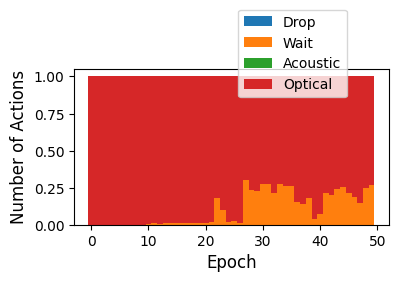

,epoch,campaign,seed,agent,Acoustic,Optical,Wait,Drop
0,2,0.0,35727.25,1.0,0.0,1.000000,0.000000,0.000000
1,4,0.0,35727.25,1.0,0.0,0.927294,0.072706,0.000000
2,6,0.0,35727.25,1.0,0.0,0.276759,0.000000,0.723241
3,8,0.0,35727.25,1.0,0.0,0.238408,0.000000,0.761592
4,10,0.0,35727.25,1.0,0.0,0.540972,0.459028,0.000000
5,12,0.0,35727.25,1.0,0.0,0.225807,0.000000,0.774193
6,14,0.0,35727.25,1.0,0.0,0.623835,0.376165,0.000000
7,16,0.0,35727.25,1.0,0.0,0.776733,0.209596,0.013672
8,18,0.0,35727.25,1.0,0.0,0.710017,0.289983,0.000000
9,20,0.0,35727.25,1.0,0.0,0.724338,0.275662,0.000000


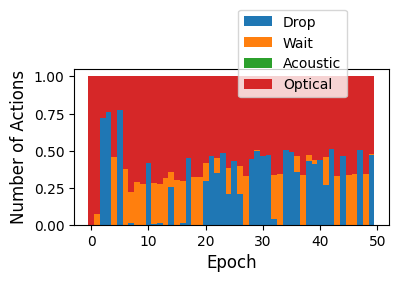

,epoch,campaign,seed,agent,Acoustic,Optical,Wait,Drop
0,2,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
1,4,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
2,6,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
3,8,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
4,10,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
5,12,0.0,35727.25,2.0,0.000000,1.000000,0.0,0.0
6,14,0.0,35727.25,2.0,0.309564,0.690436,0.0,0.0
7,16,0.0,35727.25,2.0,1.000000,0.000000,0.0,0.0
8,18,0.0,35727.25,2.0,1.000000,0.000000,0.0,0.0
9,20,0.0,35727.25,2.0,1.000000,0.000000,0.0,0.0


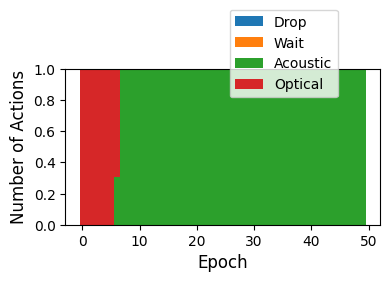

In [26]:
for i in range(3):
    throughput = df[df["agent"] == i]
    pivot_df = throughput.groupby(["epoch"]).mean().reset_index()
    actions = ["Drop", "Wait", "Acoustic", "Optical"]
    # pivot_df["Action/Optical"] = 350
    display(pivot_df)
    # Pivot the data to get actions as columns
    # Plotting
    fig, ax = plt.subplots(figsize=(8/2, 6/2))
    label_palette = dict(zip(actions, sns.color_palette("tab10", len(actions))))

    # Plot each action as a stacked bar
    bottom = None
    for action in actions:
        action_columns = [col for col in pivot_df.columns if action in col]
        action_sum = pivot_df[action_columns].sum(axis=1)
        if bottom is None:
            ax.bar(pivot_df.index, action_sum, width=1.0, label=action, color=label_palette[action])
            bottom = action_sum
        else:
            ax.bar(pivot_df.index, action_sum, width=1.0, bottom=bottom, label=action, color=label_palette[action])
            bottom += action_sum

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Number of Actions")
    # ax.set_title(f"Number of Actions {agent.split(' - ')[1]}")
    ax.legend(title="Action Type")
    # plt.ylim(0, 350)
    plt.legend(bbox_to_anchor=(0.5, 1.1), loc='center left')
    plt.tight_layout()
    tikzplotlib.save(f"action_{i}.tex")
    # plt.savefig(f"plots/actions_{agent.split(' - ')[1]}.png".replace(" ", ""), bbox_inches='tight')
    plt.show()